# Tilt Scheme Design

How many projections should a tilt series have, at which angles, and how should the dose be spread
over them? This notebook uses ETSpy's simulation tools to answer these questions for a test object,
before any time is spent at the microscope. You will learn:

* How to simulate a tilt series at any set of angles, with a given total dose
* The trade-off between the number of tilts and the dose per tilt, at a fixed total dose
* Uniform, golden-ratio and equally sloped angle schemes, and why the largest gap matters
* Why golden-ratio ordering is useful when the acquisition may have to stop early
* The cost of a limited tilt range (the missing wedge)

The same approach works for your own specimen: replace the test object with a model of it.

## Imports

In [1]:
%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np
import hyperspy.api as hs
from scipy import ndimage

import etspy.api as tomo
from etspy import simulation as sim
from etspy import utils

tomo.set_log_level("WARNING")
rng = np.random.default_rng(0)

## Test Object and Scores

The test object is the same as in the [reconstruction notebook](reconstruction_methods.ipynb): the
cross-section of a needle with a dense block, a small particle and three thin bars, 2, 4 and 8
pixels wide. It is reconstructed with SIRT (50 iterations), and scored by the error relative to the
true density and by the widths of the bars.

`simulate` projects the object at any list of angles. The **total dose** is fixed and shared
equally between the projections, so a series with twice as many projections has half the dose in
each.

In [2]:
n = 192
yy, xx = np.mgrid[:n, :n] - (n - 1) / 2
obj = np.zeros((n, n), np.float32)
obj[xx**2 + yy**2 < 80**2] = 1.0
obj[(abs(yy + 30) < 25) & (abs(xx) < 50)] = 2.0
bar_centres = (-40, -5, 30)
for c, w in zip(bar_centres, (2, 4, 8)):
    obj[(abs(yy - 30) < 20) & (abs(xx - c) < w / 2)] = 2.0
obj[(xx - 45) ** 2 + (yy + 55) ** 2 < 5**2] = 2.0
obj = ndimage.gaussian_filter(obj, 0.7)
model = np.repeat(obj[np.newaxis], 2, axis=0)

TOTAL_DOSE = 4500       # counts per unit of projected density, summed over the series


def simulate(angles, total_dose=TOTAL_DOSE):
    """Tilt series at the given angles, with the total dose shared between them."""
    series = sim.create_model_tilt_series(model, angles=np.asarray(angles, float))
    dose = total_dose / len(angles)
    series.data = rng.poisson(series.data * dose).astype(np.float32) / dose
    return series


def reconstruct(series):
    return series.reconstruct("SIRT", iterations=50, constrain=True, show_progressbar=False)


def error(rec):
    return np.linalg.norm(rec.data[0] - obj) / np.linalg.norm(obj)


def score(angles, repeats=2, total_dose=TOTAL_DOSE):
    """Mean error over independent noise realizations, and the last reconstruction."""
    errs, rec = [], None
    for _ in range(repeats):
        rec = reconstruct(simulate(angles, total_dose))
        errs.append(error(rec))
    return float(np.mean(errs)), rec


def max_gap(angles):
    """Largest angular gap (degrees), counting the wrap-around at 180 degrees."""
    a = np.sort(np.mod(angles, 180))
    return float(np.max(np.diff(np.r_[a, a[0] + 180])))

## Number of Tilts at a Fixed Total Dose

With the total dose fixed, more projections means less dose and more noise in each one. The
reconstruction collects the dose from all of them, so the noise in the result hardly depends on
how it is divided; but fewer projections leave larger gaps between the measured directions,
which show as streaks. So, as long as each projection still has enough signal to be aligned,
**more projections with less dose each** is better.

The sweep is run at two total doses. At the higher dose (4500, used for the rest of the notebook)
the error grows steadily below about 45 tilts. At a ten times lower dose, noise dominates and the
number of tilts matters much less, until the streaks take over below about 20.

tilts: [90, 60, 45, 30, 20, 12]
error, total dose 4500: [0.065, 0.065, 0.066, 0.071, 0.084, 0.104]
error, total dose 450: [0.101, 0.096, 0.095, 0.093, 0.097, 0.11]


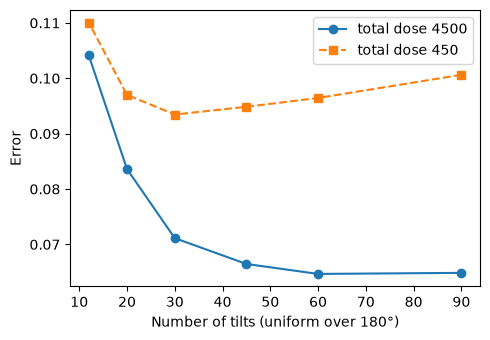

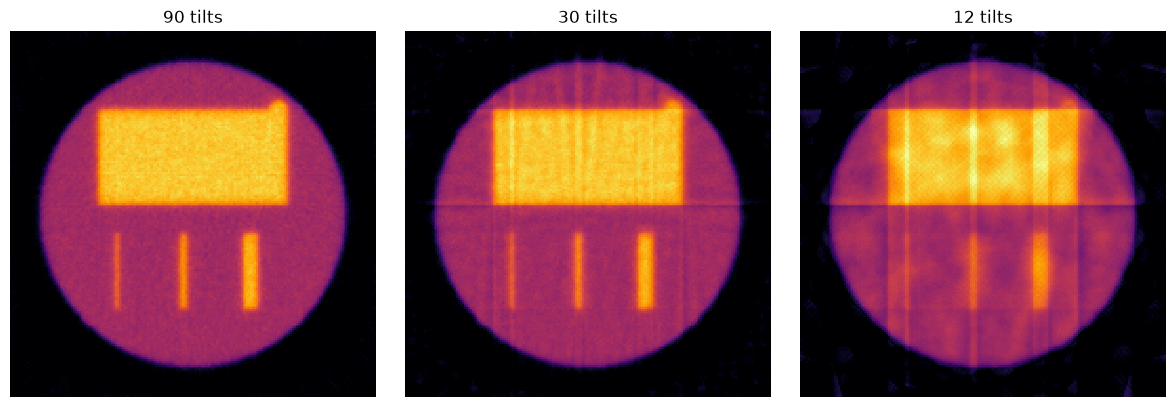

In [3]:
counts = [90, 60, 45, 30, 20, 12]
low_dose = TOTAL_DOSE / 10
by_count = {N: score(np.arange(N) * 180 / N - 90) for N in counts}
by_count_low = {N: score(np.arange(N) * 180 / N - 90, total_dose=low_dose) for N in counts}

print("tilts:", counts)
print(f"error, total dose {TOTAL_DOSE}:", [round(by_count[N][0], 3) for N in counts])
print(f"error, total dose {low_dose:.0f}:", [round(by_count_low[N][0], 3) for N in counts])

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(counts, [by_count[N][0] for N in counts], "o-", label=f"total dose {TOTAL_DOSE}")
ax.plot(counts, [by_count_low[N][0] for N in counts], "s--", label=f"total dose {low_dose:.0f}")
ax.set(xlabel="Number of tilts (uniform over 180\u00b0)", ylabel="Error")
ax.legend()
fig.tight_layout()

hs.plot.plot_images(
    [hs.signals.Signal2D(by_count[N][1].data[0]) for N in (90, 30, 12)],
    per_row=3, cmap="inferno", vmin=0, vmax=2.3, axes_decor="off", colorbar=None,
    label=[f"{N} tilts" for N in (90, 30, 12)],
)
plt.gcf().set_size_inches(12, 4)
plt.tight_layout()

## Angle Schemes with the Same Number of Tilts

With 30 projections over 180\u00b0, compare:

* **uniform**: 6\u00b0 steps
* **golden ratio**: each angle is the previous one plus 180\u00b0 divided by the golden ratio,
  wrapped into the range (`utils.calc_golden_ratio_angles`); the angles fill the range evenly but
  not exactly uniformly
* **equally sloped (EST)**: angles with equal steps in tan \u03b8 rather than in \u03b8
  (`utils.calc_est_angles`), designed for Fourier-based reconstruction; denser near
  0\u00b0 and 90\u00b0
* **uniform with one gap**: 31 uniform steps with one projection left out, which leaves one gap
  of twice the step
* **random**: 30 angles drawn at random

The error tracks the largest gap between neighbouring angles more than anything else.

scheme             tilts  largest gap   error
uniform               30         6.0°   0.071
golden ratio          30        10.0°   0.086
EST (28)              28         8.1°   0.083
uniform, one gap      30        11.6°   0.083
random                30        22.6°   0.125


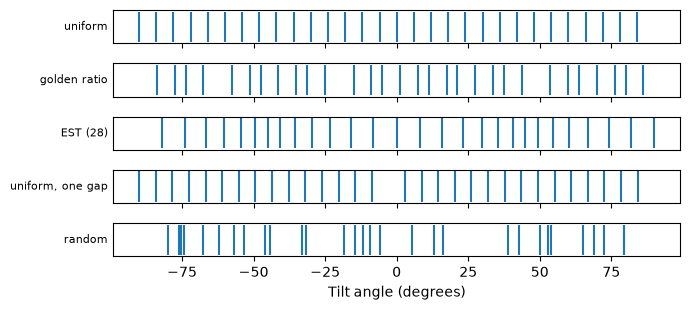

In [4]:
N = 30
est = utils.calc_est_angles(14)                    # 28 angles
schemes = {
    "uniform": np.arange(N) * 180 / N - 90,
    "golden ratio": np.sort(utils.calc_golden_ratio_angles(180, N)),
    f"EST ({len(est)})": est,
    "uniform, one gap": np.delete(np.arange(N + 1) * 180 / (N + 1) - 90, N // 2),
    "random": np.sort(rng.uniform(-90, 90, N)),
}
by_scheme = {k: score(a) for k, a in schemes.items()}

print(f"{'scheme':18s} {'tilts':>5s} {'largest gap':>12s} {'error':>7s}")
for k, a in schemes.items():
    print(f"{k:18s} {len(a):5d} {max_gap(a):11.1f}\u00b0 {by_scheme[k][0]:7.3f}")

fig, ax = plt.subplots(len(schemes), 1, figsize=(7, 3.2), sharex=True)
for a_, (k, a) in zip(ax, schemes.items()):
    a_.vlines(a, 0, 1)
    a_.set_yticks([])
    a_.set_ylabel(k, rotation=0, ha="right", va="center", fontsize=8)
ax[-1].set_xlabel("Tilt angle (degrees)")
fig.tight_layout()

## Stopping Early: Golden-Ratio Ordering

The real strength of the golden-ratio scheme is its **order**. Each new angle falls in the
largest remaining gap, so *any* number of the first projections covers the range nearly evenly.
An acquisition can then stop at any point (for example when the specimen starts to change under
the beam) and still give a usable series. A uniform series acquired in order from one end
leaves the rest of the range empty if it stops early, and a uniform series acquired in several
interleaved passes is only even at the end of each pass.

golden ratio, error after 15 / 30 / 60 projections: [0.123 0.085 0.069]


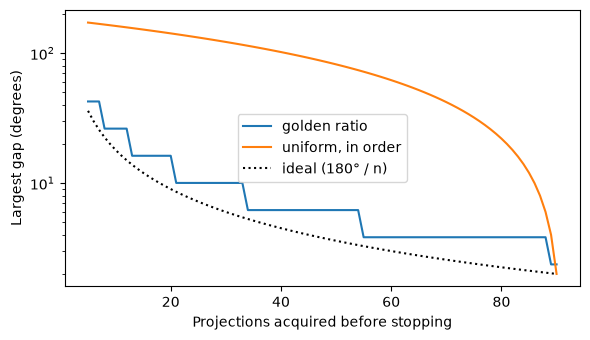

In [5]:
golden = utils.calc_golden_ratio_angles(180, 90)    # in acquisition order
sequential = np.arange(90) * 2.0 - 90               # in order from -90
stops = np.arange(5, 91)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(stops, [max_gap(golden[:k]) for k in stops], label="golden ratio")
ax.plot(stops, [max_gap(sequential[:k]) for k in stops], label="uniform, in order")
ax.plot(stops, 180 / stops, "k:", label="ideal (180\u00b0 / n)")
ax.set(xlabel="Projections acquired before stopping", ylabel="Largest gap (degrees)",
       yscale="log")
ax.legend()
fig.tight_layout()

err_golden = [score(golden[:k], repeats=1)[0] for k in (15, 30, 60)]
print("golden ratio, error after 15 / 30 / 60 projections:", np.round(err_golden, 3))

## Where the Grid Falls

With few projections, the result can also depend on where the grid of angles falls relative to
the object. This object has edges parallel to its x- and y-axes, which are best measured by
projections along them (0\u00b0 and 90\u00b0). With 20 tilts in 9\u00b0 steps, shifting the start
angle moves the grid onto or off these directions:

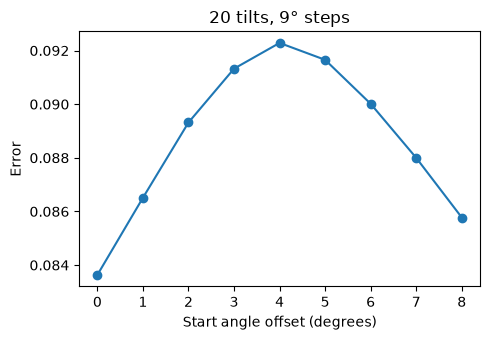

In [6]:
offsets = np.arange(0, 9)
by_offset = [score(np.arange(20) * 9.0 - 90 + o)[0] for o in offsets]

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(offsets, by_offset, "o-")
ax.set(xlabel="Start angle offset (degrees)", ylabel="Error", title="20 tilts, 9\u00b0 steps")
fig.tight_layout()

The effect is real but specific to the object: for a crystalline or layered specimen with known
facets, a grid that includes the directions along the facets helps. Without such knowledge, use
more tilts rather than relying on a particular start angle.

## Tilt Range: the Missing Wedge

Most specimens can only be tilted to about \u00b170\u00b0. Here the number of tilts and the total
dose are fixed, and the range is reduced. The directions that are never measured blur the edges
that run along the beam direction at 0\u00b0, and the error grows quickly as the range shrinks. A
needle-shaped specimen in a tomography holder that rotates through 180\u00b0 avoids this
altogether.

180 degrees: error 0.067


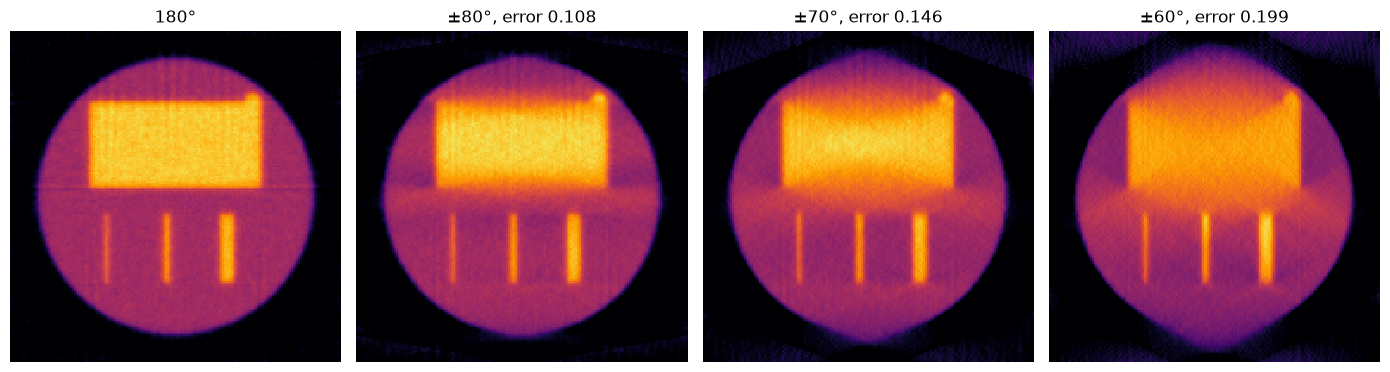

In [7]:
ranges = [180, 160, 140, 120]
by_range = {}
for r in ranges:
    if r == 180:
        a = np.arange(45) * 4.0 - 90
    else:
        a = np.linspace(-r / 2, r / 2, 45)
    by_range[r] = score(a)

hs.plot.plot_images(
    [hs.signals.Signal2D(by_range[r][1].data[0]) for r in ranges],
    per_row=4, cmap="inferno", vmin=0, vmax=2.3, axes_decor="off", colorbar=None,
    label=["180\u00b0" if r == 180 else f"\u00b1{r // 2}\u00b0, error {by_range[r][0]:.3f}"
           for r in ranges],
)
plt.gcf().set_size_inches(14, 4)
plt.tight_layout()
print("180 degrees: error %.3f" % by_range[180][0])

## Summary

* At a fixed total dose, spread it over more projections, down to the dose at which each
  projection can still be aligned
* Avoid gaps: the largest gap between neighbouring angles matters more than the number of tilts.
  Here, one skipped projection in a 30-tilt series costs about as much as using only 20 evenly
  spaced tilts
* Use golden-ratio ordering when the acquisition may have to stop early, or when the specimen
  changes under the beam
* Use the full 180\u00b0 range when the specimen and holder allow it
* Test a scheme on a model of your own specimen before using it